[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S07/2_Practica/en_clase/S07_04_roc_pr_desbalance_en_clase.ipynb)

# S07 · 04 — Curvas ROC y PR, y qué hacer con clases desbalanceadas · versión en clase

⏱ 15 min en clase · Sprint 7 · M3 (UD 3.4)

**Contexto TurisData.** Imagina un alojamiento con clientes muy fieles donde **solo el 6 %** de las reservas se cancela. Un modelo que diga siempre «no cancelará» acertaría el 94 %… y sería completamente inútil. Cuando el evento que nos importa es **raro** (cancelaciones, fraudes, averías), la exactitud engaña y hay que usar otras herramientas.

**Este cuaderno tiene 1 ejercicio**, el que se hace en el aula. La paradoja de la exactitud, la curva PR, los tres remedios del desbalance, el ajuste del umbral, el mini-reto y las preguntas de reflexión están en el cuaderno completo. Su ejercicio 2 es el de este.

**Cómo usar este cuaderno** (tiene dos partes):

- **Parte A · Ejecutar** (aquí abajo): de arriba abajo, cada celda de código lleva encima su título con un símbolo:
    - ⚙️ **Preparación**: se ejecuta sola, pulsa ▶ y sigue.
    - 👀 **Ejemplo**: pulsa ▶, mira el resultado y responde las preguntas 🧠 (no hay que escribir código). Las respuestas están en la Parte B.
    - ✏️ **Ejercicio**: tu turno. Cambia los `...` y pulsa ▶. Si sale **✔**, responde las preguntas 🧠 y sigues. Para comprobar tu código, tienes la solución de referencia ✅ en la Parte B.
- **Parte B · Explicación** (al final): para cada celda, **qué hace**, **qué resultado debe salir** y, en los ejemplos, las **respuestas** a las preguntas 🧠 y, en los ejercicios, la **solución de referencia** ✅ para comprobar tu código. Ábrela cuando quieras entender una celda, comprobar tus respuestas o no te salga. Usa el índice de la izquierda (☰) para saltar.

# Parte A · Ejecutar

### ⚙️ A1 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [1]:
#@title A1 · ▶ Ejecuta esta celda primero (no hace falta leerla)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils import resample
from sklearn.base import clone
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
                             precision_score, recall_score, accuracy_score)

warnings.filterwarnings("ignore", category=UserWarning)
SEMILLA = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["temporada_alta"] = df["fecha_llegada"].dt.month.isin([1, 2, 3, 7, 8, 12]).astype(int)

# Escenario simulado: conservamos todas las no canceladas y una parte de las canceladas (≈ 6 %)
neg = df[df["cancelada"] == 0]
pos = df[df["cancelada"] == 1].sample(n=int(len(neg) * 0.064), random_state=SEMILLA)
raro = pd.concat([neg, pos]).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
print(f"Reservas: {len(raro)} · canceladas: {raro['cancelada'].sum()} ({raro['cancelada'].mean():.1%})")

columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = raro[columnas_num + columnas_cat], raro["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEMILLA, stratify=y)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), columnas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), columnas_cat),
])

def nuevo_modelo(**kwargs):
    # clone(prep): cada modelo necesita su propia copia del preprocesado (si no, se pisarían entre sí)
    return Pipeline([("prep", clone(prep)), ("clf", LogisticRegression(max_iter=1000, **kwargs))])
print("Listo ✔")

Reservas: 3453 · canceladas: 207 (6.0%)
Listo ✔


### 👀 A2 · EJEMPLO — Entrenar el modelo base y sacar sus probabilidades

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A2).

1. ¿Cuántas reservas hay en test y cuántas canceladas?
2. ¿Qué contiene `proba_base`?
3. Con solo 62 positivas en test, ¿qué cuidado hay que tener al interpretar las métricas?

In [2]:
base = nuevo_modelo().fit(X_train, y_train)
proba_base = base.predict_proba(X_test)[:, 1]
print("Reservas de test:", len(y_test), "· canceladas:", int(y_test.sum()))

Reservas de test: 1036 · canceladas: 62


### ✏️ A3 · EJERCICIO 1 de 1 — Calcular la curva ROC y el AUC

**Tu turno:** Con `y_test` y `proba_base` calcula `fpr, tpr, _ = roc_curve(...)` y `auc = roc_auc_score(...)`.

**Debe salir:** un gráfico con la curva ROC, `AUC = 0.774` y ✔ Ejercicio 1 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A3).

1. ¿Cuánto vale el AUC?
2. ¿Cómo se interpreta un AUC de 0,77?
3. ¿Qué indica que la curva quede por encima de la diagonal?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A3, **después de intentarlo**.

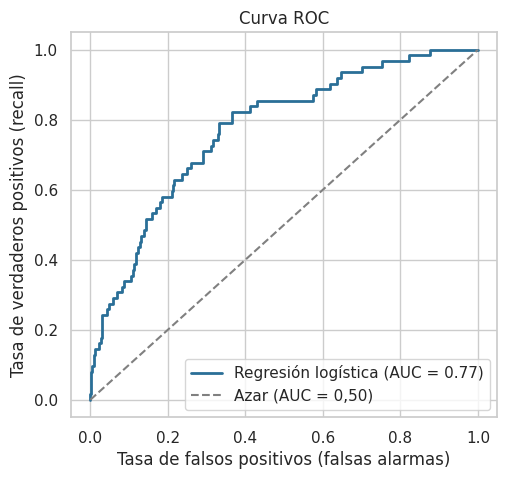

AUC = 0.774
✔ Ejercicio 1 correcto


In [3]:
# pista: roc_curve(y_test, proba_base) devuelve tres arrays; roc_auc_score(y_test, proba_base)
fpr, tpr, _ = roc_curve(y_test, proba_base)
auc = roc_auc_score(y_test, proba_base)

assert len(fpr) == len(tpr) and fpr[0] == 0 and tpr[-1] == 1, "fpr y tpr deben ser la curva ROC completa"
assert 0.6 < auc < 0.95, "El AUC de este modelo debería estar entre 0,6 y 0,95"

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, color="#2a6f97", lw=2, label=f"Regresión logística (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0,50)")
plt.title("Curva ROC")
plt.xlabel("Tasa de falsos positivos (falsas alarmas)")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.legend(loc="lower right")
plt.show()
print(f"AUC = {auc:.3f}")
print("✔ Ejercicio 1 correcto")

---

## 🏁 Fin del cuaderno de clase

El **[cuaderno completo](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S07/2_Practica/para_casa/S07_04_roc_pr_desbalance.ipynb)** trae la paradoja de la exactitud, la curva precisión–recall, los tres remedios del desbalance (pesos, submuestreo y umbral), el mini-reto de la comparativa y las preguntas de reflexión, cada ejercicio con su solución plegada en la Parte B.

# Parte B · Explicación de cada celda y de cada resultado

Cada apartado lleva el **mismo número** que su celda de la Parte A (A1, A2…). Si una celda no te sale, mira su «Si falla».

#### A1 · Preparación — Preparar las herramientas y el escenario de clase rara

> **Nota honesta:** `reservas_turisdata.csv` tiene un 46 % de cancelaciones. Para este laboratorio **simulamos** un escenario raro conservando solo una parte de las canceladas. Es un recurso didáctico: en un proyecto real no se manipula la tasa de la población de test.

- **Qué hace:**
    - Carga las herramientas: `pandas`, `numpy`, `matplotlib`, `seaborn` y, de `scikit-learn`, la regresión logística, el modelo tonto, el preprocesado, `resample` y las métricas ROC y PR.
    - `dato(...)` busca un archivo de datos del curso y, si no está, lo descarga del repositorio.
    - **Fabrica el escenario raro**: conserva todas las reservas no canceladas y solo una muestra de las canceladas (`pos`), de modo que queden ≈ 6 % (la tabla `raro`).
    - Separa `X` e `y`, reparte train y test (70 % / 30 %, estratificado) y define `prep` (el preprocesado) y `nuevo_modelo(**kwargs)`, que fabrica un pipeline nuevo cada vez (con su propia copia del preprocesado).
- **Qué debe salir:**
    - `Reservas: 3453 · canceladas: 207 (6.0%)` y `Listo ✔`.
- **Cómo leerlo:**
    - No hay que entender esta celda: solo ejecutarla **la primera**, y otra vez si reinicias el entorno.
- **Si falla:**
    - `NameError: name 'pd' is not defined` → no has ejecutado esta celda. Ejecútala y repite la que falló.

## 2. Curva ROC y AUC

#### A2 · Ejemplo — Entrenar el modelo base y sacar sus probabilidades

**Idea.** Para **cada umbral posible** medimos:
- **TPR** (tasa de verdaderos positivos = recall): cancelaciones detectadas,
- **FPR** (tasa de falsos positivos): reservas que se mantienen pero marcamos como riesgo.

La **curva ROC** dibuja TPR frente a FPR. Un modelo inútil va por la diagonal; uno bueno se pega a la esquina superior izquierda. El **AUC** (área bajo la curva) resume: 0,5 = azar; 1 = perfecto. Interpretación intuitiva: *la probabilidad de que una reserva cancelada reciba una puntuación más alta que una que no se cancela*.

- **Qué hace:**
    - `nuevo_modelo().fit(X_train, y_train)` entrena la regresión logística con su preprocesado (`base`).
    - `base.predict_proba(X_test)[:, 1]` da, para cada reserva de test, la probabilidad de cancelar (`proba_base`).
    - El `print` cuenta las reservas de test y cuántas se cancelan.
- **Qué debe salir:**
    - `Reservas de test: 1036 · canceladas: 62`.
- **Si falla:**
    - `NameError: name 'nuevo_modelo' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuántas reservas hay en test y cuántas canceladas?* → **1036** reservas y **62** canceladas (el 6 %).
2. *¿Qué contiene `proba_base`?* → Una **probabilidad de cancelar** por cada reserva de test (1036 valores entre 0 y 1).
3. *Con solo 62 positivas en test, ¿qué cuidado hay que tener al interpretar las métricas?* → Que son **poco estables**: pocas reservas más o menos detectadas cambian mucho el recall (cada positiva vale 1,6 puntos). Lo retomamos en la reflexión.

</details>

#### A3 · Ejercicio 1 — Calcular la curva ROC y el AUC

- **Qué hace:**
    - `roc_curve(y_test, proba_base)` devuelve tres arrays: la tasa de falsos positivos (`fpr`), la de verdaderos positivos (`tpr`) y los umbrales (que no usamos: `_`). Cada punto es un umbral distinto.
    - `roc_auc_score(y_test, proba_base)` calcula el área bajo esa curva, el AUC.
    - Las líneas que siguen (ya hechas) dibujan la curva y la diagonal del azar.
- **Qué debe salir:**
    - Un gráfico con una curva por encima de la diagonal (la leyenda dice `AUC = 0.77`) y `AUC = 0.774`.
    - `✔ Ejercicio 1 correcto`.
- **Si falla:**
    - `fpr y tpr deben ser la curva ROC completa` → `fpr` y `tpr` no salen de `roc_curve(...)` con `y_test` y `proba_base`.
    - `El AUC de este modelo debería estar entre 0,6 y 0,95` → `auc` no es `roc_auc_score(y_test, proba_base)` (¿has puesto `predict` en vez de las probabilidades?).
    - `NameError: name 'proba_base' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánto vale el AUC?* → **≈ 0,77** (0,774).
2. *¿Cómo se interpreta un AUC de 0,77?* → Si tomas una reserva cancelada y otra no al azar, el modelo da **más probabilidad a la cancelada en ≈ 77 % de los casos** (0,5 sería el azar).
3. *¿Qué indica que la curva quede por encima de la diagonal?* → Que el modelo **ordena mejor que el azar**. Por ejemplo, con un FPR de ≈ 0,18 (marcando como riesgo el 18 % de las reservas que se mantienen) detecta ≈ 56–58 % de las cancelaciones.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
fpr, tpr, _ = roc_curve(y_test, proba_base)
auc = roc_auc_score(y_test, proba_base)
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>